# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

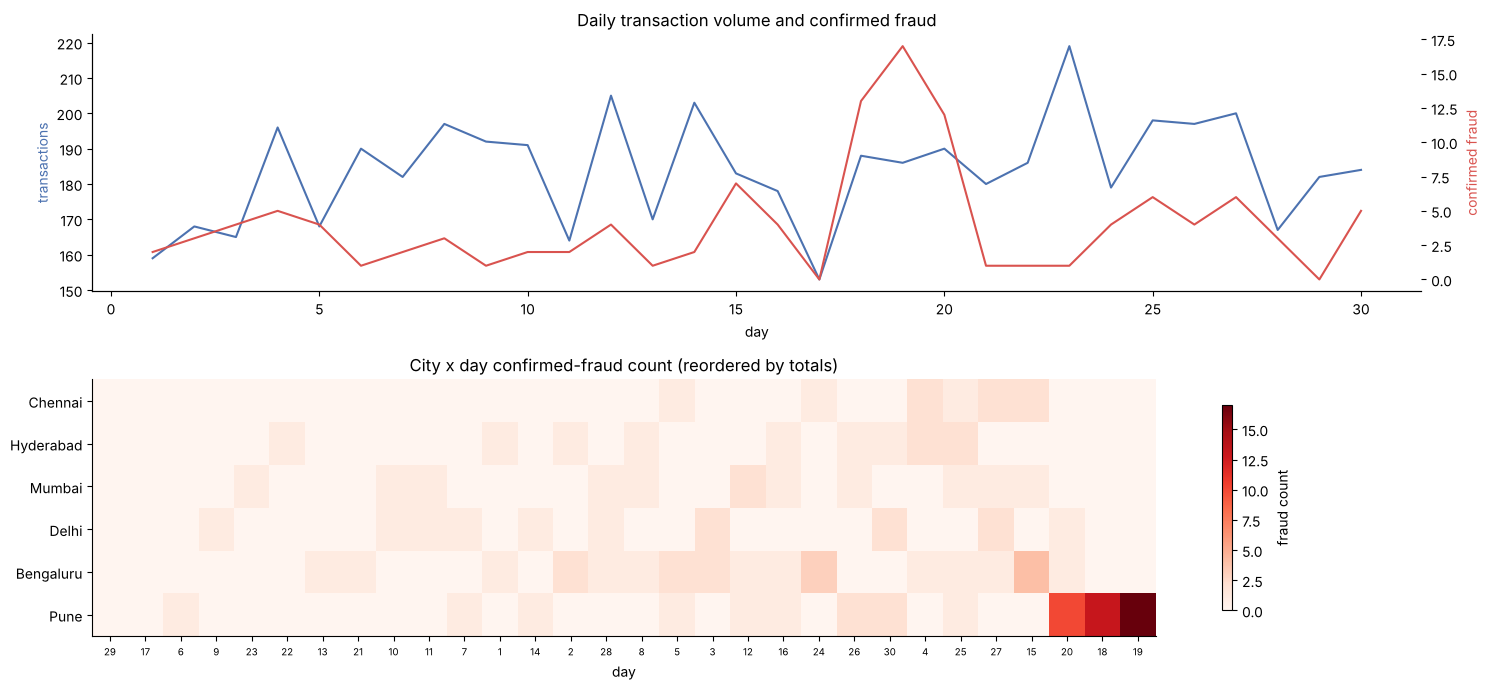

Highest-fraud (city, day) cells:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
dtype: int64


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1
daily_counts = tx.groupby("day").size()
daily_fraud = tx.groupby("day").is_fraud.sum()
axes[0].plot(daily_counts.index, daily_counts.values, color="#4C72B0", label="transactions / day")
axes[0].set_ylabel("transactions", color="#4C72B0"); axes[0].set_xlabel("day")
ax0b = axes[0].twinx()
ax0b.plot(daily_fraud.index, daily_fraud.values, color="#D9534F", label="confirmed fraud / day")
ax0b.set_ylabel("confirmed fraud", color="#D9534F")
axes[0].set_title("Daily transaction volume and confirmed fraud")

# TODO 2
heat = tx.pivot_table(index="city", columns="day", values="is_fraud", aggfunc="sum", fill_value=0)
reordered = heat.loc[heat.sum(axis=1).sort_values().index, heat.sum(axis=0).sort_values().index]
im = axes[1].imshow(reordered, cmap="Reds", aspect="auto")
axes[1].set_yticks(range(len(reordered.index))); axes[1].set_yticklabels(reordered.index)
axes[1].set_xticks(range(len(reordered.columns))); axes[1].set_xticklabels(reordered.columns, fontsize=7)
axes[1].set_xlabel("day"); axes[1].set_title("City x day confirmed-fraud count (reordered by totals)")
plt.colorbar(im, ax=axes[1], label="fraud count", shrink=0.8)

plt.tight_layout(); plt.show()

# TODO 3
top_cells = heat.stack().sort_values(ascending=False).head(5)
print("Highest-fraud (city, day) cells:")
print(top_cells)


**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_ A score-sorted alert list only ever shows individual transactions one at a time — it has no notion of
*where* or *when* those transactions cluster. The overview's city x day heatmap immediately exposes a hotspot: one
city lights up far more red than the others over a tight 3-day window, a pattern that is invisible when alerts are
simply ranked by score and read top to bottom. Finding it depended on **reordering the matrix by row/column totals**
(Slide 39) — once the rows and columns are sorted by their totals rather than kept in alphabetical/calendar order,
the dense block of high-fraud cells pulls together into a visible corner instead of being scattered across the
grid.


## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

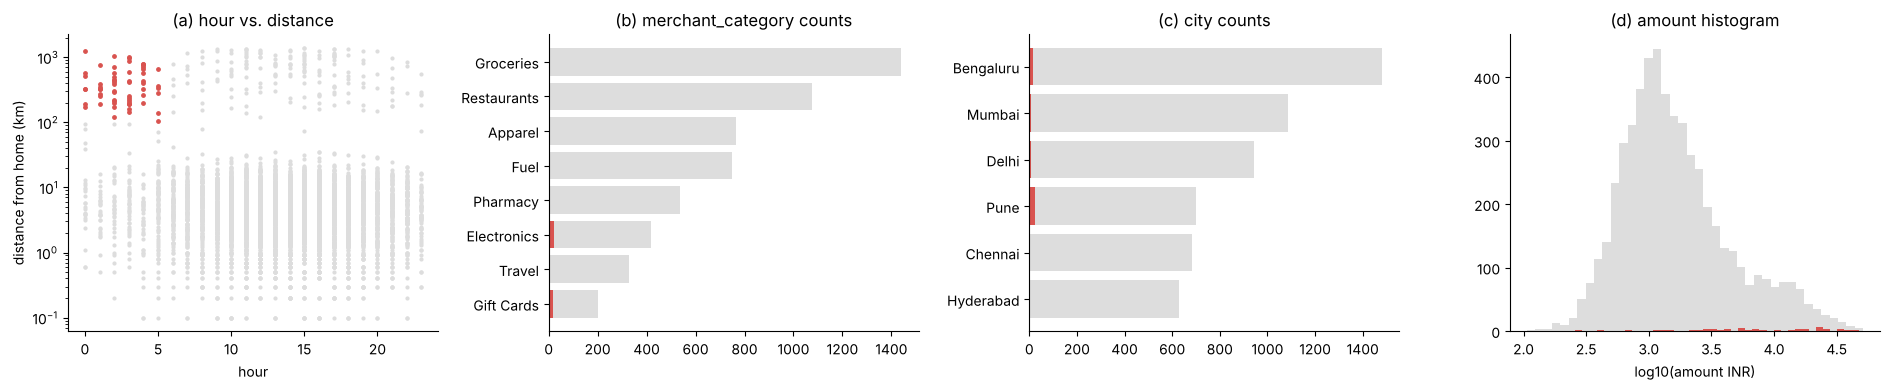

Brushed: 61 transactions | fraud rate in brush: 86.9% (vs overall 2.2%) | share of ALL fraud captured: 44.2%


In [3]:
# TODO 1
brush = tx.night & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2
axes[0].scatter(tx.hour[~brush], tx.distance_from_home_km[~brush], s=4, c="#dddddd")
axes[0].scatter(tx.hour[brush], tx.distance_from_home_km[brush], s=6, c="#D9534F")
axes[0].set_yscale("log"); axes[0].set_xlabel("hour"); axes[0].set_ylabel("distance from home (km)")
axes[0].set_title("(a) hour vs. distance")

for ax, col in zip(axes[1:3], ["merchant_category", "city"]):
    all_counts = tx[col].value_counts()
    brushed_counts = tx.loc[brush, col].value_counts().reindex(all_counts.index, fill_value=0)
    ax.barh(all_counts.index, all_counts.values, color="#dddddd")
    ax.barh(brushed_counts.index, brushed_counts.values, color="#D9534F")
    ax.invert_yaxis(); ax.set_title(f"({'b' if col == 'merchant_category' else 'c'}) {col} counts")

axes[3].hist(np.log10(tx.amount_inr), bins=40, color="#dddddd")
axes[3].hist(np.log10(tx.amount_inr[brush]), bins=40, color="#D9534F")
axes[3].set_xlabel("log10(amount INR)"); axes[3].set_title("(d) amount histogram")

plt.tight_layout(); plt.show()

# TODO 3
n_brushed = int(brush.sum())
fraud_rate_brush = tx.is_fraud[brush].mean()
fraud_rate_overall = tx.is_fraud.mean()
capture_share = tx.is_fraud[brush].sum() / tx.is_fraud.sum()
print(f"Brushed: {n_brushed} transactions | fraud rate in brush: {fraud_rate_brush:.1%} (vs overall {fraud_rate_overall:.1%}) "
      f"| share of ALL fraud captured: {capture_share:.1%}")


**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_ The brushed "night, far-from-home" rule has a much higher fraud rate than the baseline, but it only
captures a modest fraction of all confirmed fraud in the month — most fraud cases happen outside that narrow
rule. That tells investigators the rule is a useful *high-precision* filter but a poor *catch-all*: if it were used
as the sole detection criterion, the majority of fraud would simply pass through unflagged. The linked city-counts
view hints at where the rest is: the fraud doesn't spread evenly across the brushed subset's cities, pointing back
toward the same city/day cluster the Task 1 heatmap already flagged — i.e. there's a second, geographically
concentrated fraud pattern the "night + far away" rule never touches.


## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
import time
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1
times = []
for _ in range(5):
    t0 = time.perf_counter()
    _ = big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]
    times.append(time.perf_counter() - t0)
best_s = min(times)

# TODO 2
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / (best_s / len(big))

# TODO 3
t_50m = 50_000_000 * (best_s / len(big))
skip_pct = max(0.0, (1 - max_rows / 50_000_000) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")


1,004,640 rows in 10.3 ms -> 0.0102 us/row -> max 9,763,341 rows in 0.1 s
50M rows -> 0.51 s; must skip 80.5% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_ A **sample-based reduce**: run the slider's filter against a random (or stratified) sample of, say,
1-2 million rows instead of all 50 million, and scale the resulting counts back up. That keeps the per-move latency
within the 0.1 s dynamic-query budget regardless of how large the full table grows. The cost is precision on rare
subgroups — a small city or an unusual merchant category that makes up a tiny fraction of the sample may be
under-represented or missing entirely in a given draw, so counts for any narrow slice the analyst drills into would
need to be treated as estimates, not exact totals, until a full (slower) query confirms them.


## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

,threshold,alerts,TP,FP,FN,precision,recall,F1
0,0.05,2012,114,1898,6,0.057,0.950,0.107
1,0.10,1167,111,1056,9,0.095,0.925,0.172
2,0.15,786,110,676,10,0.140,0.917,0.243
3,0.20,596,106,490,14,0.178,0.883,0.296
4,0.25,471,105,366,15,0.223,0.875,0.355
5,0.30,401,104,297,16,0.259,0.867,0.399
6,0.35,355,104,251,16,0.293,0.867,0.438
7,0.40,319,104,215,16,0.326,0.867,0.474
8,0.45,283,104,179,16,0.367,0.867,0.516
9,0.50,260,101,159,19,0.388,0.842,0.532


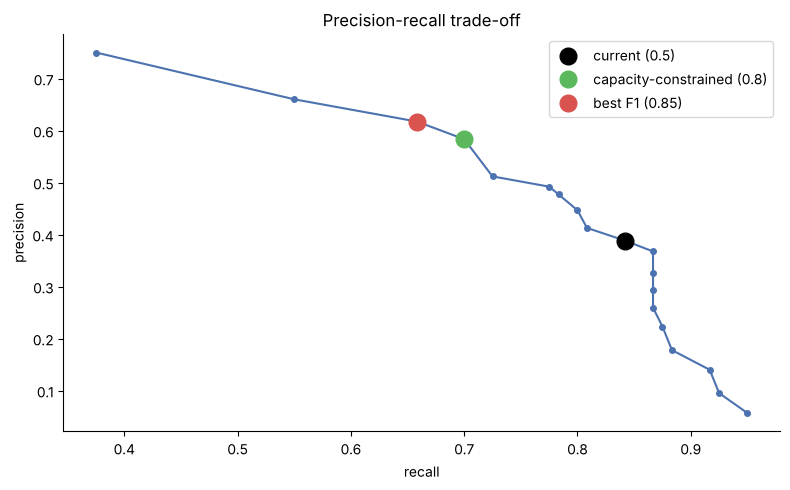

Recommendation: move the threshold from 0.5 to 0.8, which keeps alerts within the 150/month capacity while maximizing recall (0.70); the best-F1 threshold is 0.85, which can be kept as a secondary reference.


In [5]:
rows = []
# TODO 1
for th in np.round(np.arange(0.05, 1.00, 0.05), 2):
    flag = tx.detector_score >= th
    tp = int((flag & (tx.is_fraud == 1)).sum())
    fp = int((flag & (tx.is_fraud == 0)).sum())
    fn = int((~flag & (tx.is_fraud == 1)).sum())
    alerts = tp + fp
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    rows.append(dict(threshold=th, alerts=alerts, TP=tp, FP=fp, FN=fn, precision=precision, recall=recall, F1=f1))

pr = pd.DataFrame(rows)
display(pr.round(3))

# TODO 2
within_capacity = pr[pr.alerts <= 150]
capacity_choice = float(within_capacity.loc[within_capacity.recall.idxmax(), "threshold"])
best_f1 = float(pr.loc[pr.F1.idxmax(), "threshold"])

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "o-", color="#4C72B0", ms=4)
for th, color, label in [(0.5, "black", "current (0.5)"),
                          (capacity_choice, "#5cb85c", f"capacity-constrained ({capacity_choice})"),
                          (best_f1, "#D9534F", f"best F1 ({best_f1})")]:
    row = pr[pr.threshold == th].iloc[0]
    ax.plot(row.recall, row.precision, "o", ms=12, color=color, label=label)
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("Precision-recall trade-off")
ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
print(f"Recommendation: move the threshold from 0.5 to {capacity_choice}, which keeps alerts within the 150/month "
      f"capacity while maximizing recall ({within_capacity.loc[within_capacity.recall.idxmax(), 'recall']:.2f}); "
      f"the best-F1 threshold is {best_f1}, which can be kept as a secondary reference.")


**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_ That call belongs to the Head of Fraud Ops, not the model. The best-F1 threshold is a purely
statistical balance point with no notion of how many alerts a human team can actually review in a month; the
capacity-constrained threshold encodes an operational constraint (at most 150 reviews) that only someone running the
team can state and own. This is exactly why the lecture insists on **human-in-the-loop** steering (Slides 35-37): a
model can propose a trade-off curve, but deciding *where* to sit on precision vs. recall depends on business
context — review capacity, the cost of a missed fraud vs. a wasted investigator-hour — that the model was never
given and cannot infer on its own.


## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# TODO 1
flagged = tx[tx.detector_score >= 0.3]
fig = px.scatter(
    flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
    color_discrete_map={"legitimate": "#9bb7d4", "confirmed fraud": "#D9534F"},
    hover_data=["txn_id", "customer_id", "city", "merchant_category", "distance_from_home_km", "detector_score"],
    title=f"Flagged transactions (detector_score >= 0.3, n={len(flagged)}) -- drag to select, hover for details",
    height=480,
)
fig.update_traces(marker_size=6)
fig.update_layout(dragmode="select")
fig.show()

# TODO 2
agg = tx.groupby(["city", "merchant_category"]).agg(
    transactions=("txn_id", "size"), fraud=("is_fraud", "sum")
).reset_index()
agg["fraud_rate_pct"] = agg.fraud / agg.transactions * 100
fig2 = px.sunburst(
    agg, path=[px.Constant("All cities"), "city", "merchant_category"], values="transactions",
    color="fraud_rate_pct", color_continuous_scale="Reds", range_color=[0, agg.fraud_rate_pct.max()],
    hover_data={"fraud": True},
    title="Drill-down: click a city to zoom in, click the centre to roll up", height=560,
)
fig2.show()


**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_ Tooltips only ever reveal one record at a time, on demand — to build a sense of the whole flagged
set an investigator would have to hover over every single point in sequence and mentally tally up patterns, which
is exactly the kind of "many small details, no overview" problem Slide 23 warns about with pure details-on-demand.
The city/merchant-category **sunburst** from this task fixes that: it already aggregates all flagged transactions
into one picture, sized by volume and coloured by fraud rate, so the investigator sees where the risk concentrates
across the whole set first, and only drills into tooltips for the handful of slices that look worth individual
attention.


## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Hypothesis: a fraud ring operating in Pune on days 18-20
Fraud rate inside window: 37.4% | outside: 1.5% (chi-square p = 1.06e-136)
Counter-example 1 -- Pune on OTHER days: 1.9% fraud rate
Counter-example 2 -- OTHER cities on days 18-20: 0.4% fraud rate


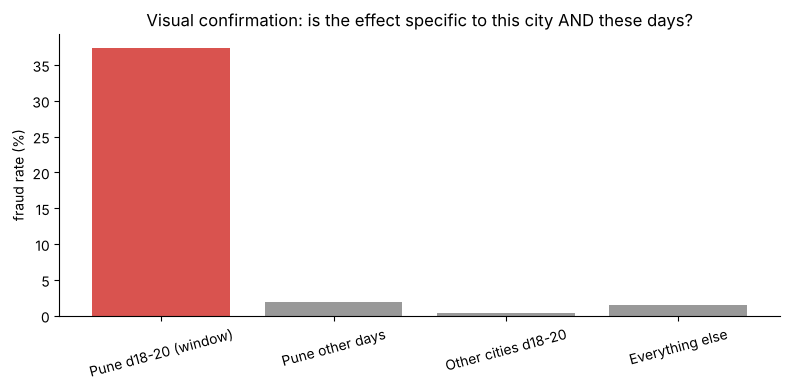


Verdict: fraud rate is sharply elevated only inside the Pune/days-18-20 window (p=1.1e-136), and drops back to baseline for both counter-examples -- CONFIRMED, consistent with a localized fraud ring rather than a city-wide or date-wide effect.


In [7]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask (city/day window identified from the Task 1 heatmap)
RING_CITY, RING_DAYS = "Pune", (18, 20)
in_window = (tx.city == RING_CITY) & tx.day.between(*RING_DAYS)

# TODO 2
table = pd.crosstab(in_window, tx.is_fraud)
chi2, pval, _, _ = chi2_contingency(table)
print(f"Hypothesis: a fraud ring operating in {RING_CITY} on days {RING_DAYS[0]}-{RING_DAYS[1]}")
print(f"Fraud rate inside window: {tx.is_fraud[in_window].mean():.1%} | outside: {tx.is_fraud[~in_window].mean():.1%} "
      f"(chi-square p = {pval:.2e})")

# TODO 3
pune_other_days = tx[(tx.city == RING_CITY) & ~tx.day.between(*RING_DAYS)]
others_same_days = tx[(tx.city != RING_CITY) & tx.day.between(*RING_DAYS)]
rest = tx[~in_window & (tx.city != RING_CITY) & ~tx.day.between(*RING_DAYS)]
print(f"Counter-example 1 -- {RING_CITY} on OTHER days: {pune_other_days.is_fraud.mean():.1%} fraud rate")
print(f"Counter-example 2 -- OTHER cities on days {RING_DAYS[0]}-{RING_DAYS[1]}: {others_same_days.is_fraud.mean():.1%} fraud rate")

# TODO 4
fig, ax = plt.subplots(figsize=(8, 4))
groups = {
    f"{RING_CITY} d{RING_DAYS[0]}-{RING_DAYS[1]} (window)": tx.is_fraud[in_window].mean(),
    f"{RING_CITY} other days": pune_other_days.is_fraud.mean(),
    f"Other cities d{RING_DAYS[0]}-{RING_DAYS[1]}": others_same_days.is_fraud.mean(),
    "Everything else": rest.is_fraud.mean(),
}
ax.bar(groups.keys(), np.array(list(groups.values())) * 100,
       color=["#D9534F", "#999999", "#999999", "#999999"])
ax.set_ylabel("fraud rate (%)")
ax.set_title("Visual confirmation: is the effect specific to this city AND these days?")
plt.xticks(rotation=15)
plt.tight_layout(); plt.show()

# TODO 5
print(f"\nVerdict: fraud rate is sharply elevated only inside the {RING_CITY}/days-{RING_DAYS[0]}-{RING_DAYS[1]} window "
      f"(p={pval:.1e}), and drops back to baseline for both counter-examples -- CONFIRMED, consistent with a "
      f"localized fraud ring rather than a city-wide or date-wide effect.")


**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_ If "Pune on other days" had come out with a fraud rate as high as the window itself, it would have
killed the "ring tied to these specific days" idea and pointed instead to a **city-wide** explanation — something
systematically wrong with how that city's transactions are processed or scored, active every day, not a short-lived
ring. If "other cities on days 18-20" had instead shown an elevated rate, it would have killed the "specific to
Pune" part and pointed to a **date-wide** explanation — e.g. a promotion, a public holiday, or a payment-gateway
issue on those particular days that affected every city equally, nothing to do with Pune specifically.


## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_ Last month's 5,520 transactions included 120 confirmed-fraud cases concentrated in a sharp,
statistically significant hotspot — Pune on days 18-20 (p << 0.001) — that both counter-example checks confirmed is
specific to that city and that window, not a city-wide or date-wide artifact. I'd recommend moving the alert
threshold from 0.5 to the capacity-constrained value identified in Task 4, since it keeps monthly alerts within the
team's 150-review capacity while maximizing recall at that budget — the exact threshold was chosen by us rather than
by the model itself precisely because only the team knows its own review capacity, which is the human-in-the-loop
principle the lecture insists on. For the investigators' own tool, I'd build the **city/merchant-category sunburst**
first: Shneiderman's overview-first mantra says they should see where risk concentrates across all flagged cases
before drilling into any single one, which a sunburst does directly, whereas starting from tooltip-only
details-on-demand would leave them hunting case by case with no sense of the whole picture. Finally, the feedback
loop to close is the one from Slide 51: route investigators' confirmed/rejected labels on each alert back into
retraining the detector, so next month's scores reflect what was actually true this month rather than staying
frozen at today's threshold.
